# Geometrically cohesive oriented hierarchies: reproducing the figures

This notebook reproduces the five figures of the paper *Geometrically cohesive oriented hierarchies:
exact quadratic computation and limits of a marginal selection*:

| Figure | Content | Section |
|---|---|---|
| 1 | Running times of the greedy selection and of the three exact implementations | 6.4 |
| 2 | Effect of the threshold $\alpha$ on fidelity and class recovery (regime U, $n=200$) | 6.5 |
| 3 | Number of components $K$ and of intervals $I/n^2$ of the greedy forest | 6.7 |
| 4 | Exact reference and greedy hierarchies on the fraction-subtraction data | 7.3 |
| 5 | Bootstrap support of the implications (exact reference and IITA) | 7.6 |

By default the synthetic campaigns run in **quick mode** (fewer matrices and sizes, about one minute), so that the
figures appear quickly in Colab or Binder. Set `QUICK = False` to run the full protocol of Section 6.3, which takes
about 10-15 minutes. Running times depend on the machine; the other quantities are reproduced up to the
sampling variability of the random matrices.

Repository: https://github.com/Fidy-Heritiana/Oriented-Hierarchies-SIA

In [1]:
# Setup: in Colab, clone the repository; locally or in Binder, use the current folder.
import os, sys
if not os.path.exists("code/ohier.py"):
    if not os.path.exists("Oriented-Hierarchies-SIA"):
        !git clone -q https://github.com/Fidy-Heritiana/Oriented-Hierarchies-SIA.git
    os.chdir("Oriented-Hierarchies-SIA")
sys.path.insert(0, "code")

%matplotlib inline
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 110

import synthetic as syn
import figures_realdata as real

QUICK = True   # set to False for the full protocol of Section 6.3
if QUICK:
    TIMING = dict(ns=(20, 40, 80, 160), matrices=3, repeats=1)
    FIDELITY = dict(ns=(200,), matrices=10)
    GROWTH = dict(ns=(50, 100, 200, 400), matrices=10)
else:
    TIMING, FIDELITY, GROWTH = {}, {}, {}

## Figure 1 - Running times

Regimes U (uniform intensities), P (all pair cohesions positive) and O (latent order). The greedy selection starts
from the intensity matrix $M$; the exact implementations start from the pair cohesions. The three exact
implementations (scan, heap of Algorithm 3, matrix tournament of Theorem 5) must return the same sequence of merges;
the campaign checks it on every matrix.

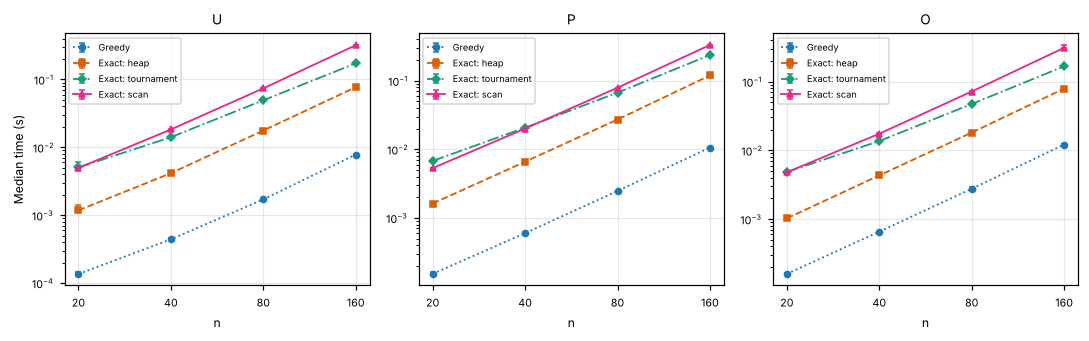

Median paired ratios at the largest n (Table 4 and Section 6.4):
        scan/heap  scan/tournament
regime                            
O            4.00             1.85
P            2.77             1.40
U            4.15             1.86


In [2]:
timing = syn.timing_campaign(**TIMING, verbose=False)
fig = syn.fig_timing(timing)
plt.show()
tex, ratios = syn.table_timing(timing)
print("Median paired ratios at the largest n (Table 4 and Section 6.4):")
print(ratios.round(2))

## Figure 2 - Effect of the threshold

Regime U, $n=200$. Left: Jaccard distance between the exact hierarchy $\mathcal H_G$ and the greedy hierarchy
$\mathcal H_N$, with and without singletons, and the proportion of greedy merges with zero cohesion. Right: recall of
the reference classes among the intervals of the greedy forest, and precision of the intervals.

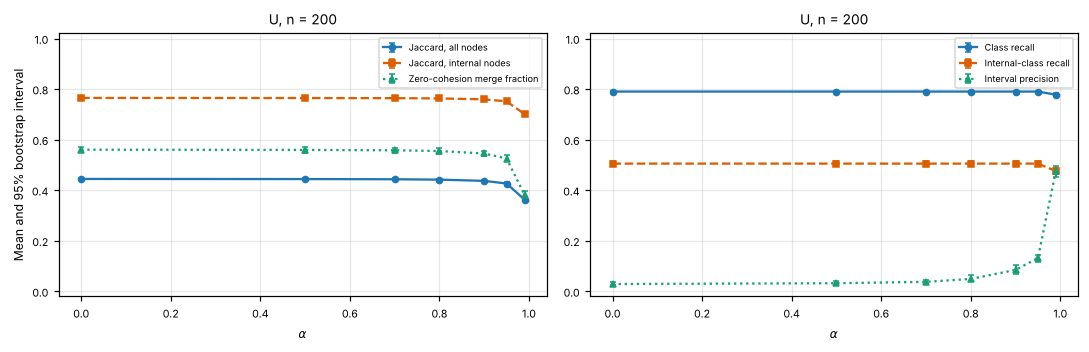

Tables 5 and 6 (n = 200, alpha = 0.7):
          D_J  D_J_int  zero_fraction   K_N   K_G       I  recall  precision
regime                                                                      
U       0.444    0.764          0.558   5.4  52.8  8112.2   0.790      0.038
P       0.500    0.804          0.000   5.0   1.0  9473.4   0.690      0.034
O       0.330    0.650          0.000  58.8  61.8   498.2   0.819      0.557


In [3]:
fidelity = syn.fidelity_campaign(**FIDELITY, verbose=False)
fig = syn.fig_fidelity(fidelity, regime="U", n=200)
plt.show()
tex5, tex6, means, bias = syn.table_fidelity(fidelity)
print("Tables 5 and 6 (n = 200, alpha = 0.7):")
print(means[["D_J", "D_J_int", "zero_fraction", "K_N", "K_G", "I", "recall", "precision"]].round(3))

## Figure 3 - Growth of the number of components

Regime U, $\alpha=0.7$: means of the number $K$ of paths of the greedy forest and of $I/n^2$, with 95% bootstrap
intervals. No limiting behaviour is inferred from this finite range.

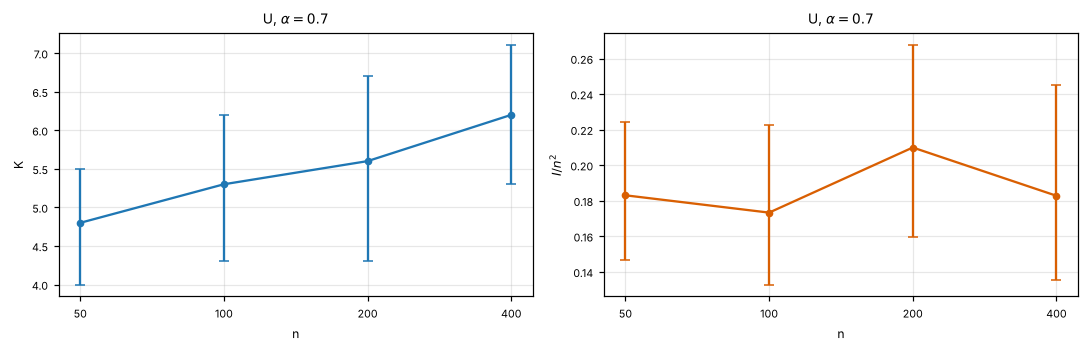

       K  I_over_n2
n                  
50   4.8      0.183
100  5.3      0.173
200  5.6      0.210
400  6.2      0.183


In [4]:
growth = syn.growth_campaign(**GROWTH, verbose=False)
fig = syn.fig_growth(growth)
plt.show()
print(growth.groupby("n")[["K", "I_over_n2"]].mean().round(3))

## Figure 4 - Hierarchies on the fraction-subtraction data

Responses of 536 students to 20 items (R package CDM). Intensities: entropic implication intensity with the
constraint $m_x \le m_y$. The second label line gives the attributes required by each item in the Q-matrix.

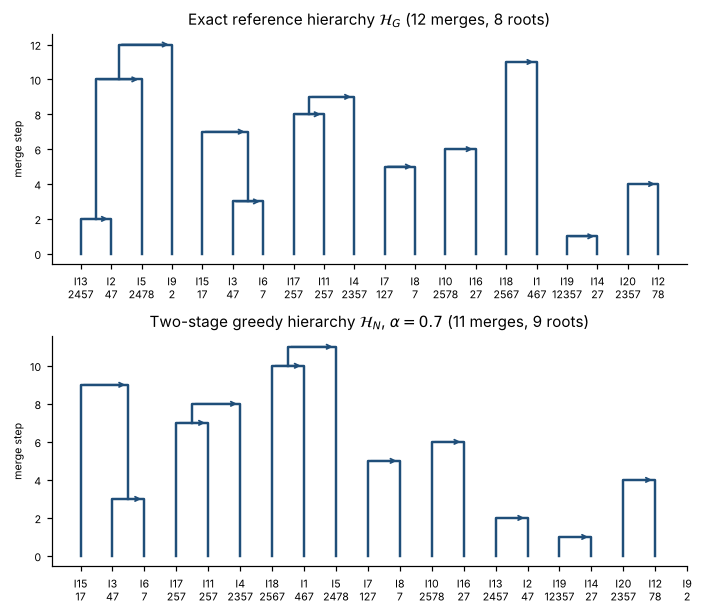

In [5]:
fig = real.fig_hierarchies()
plt.show()

## Figure 5 - Bootstrap support of the implications

Proportion of $B=1000$ bootstrap replicates in which $x \to y$ is an implication of the exact reference hierarchy
(left) or of the IITA quasi-order (right). Marks for a support of at least 0.5: `+` consistent with the Q-matrix,
`=` equal attribute sets, `x` reversed, `o` incomparable. The stable reversed implication I11 $\to$ I4 is discussed in
Section 7.6.

The supports are read from `results/final/`. To recompute them (about 2 minutes), uncomment the first two lines.

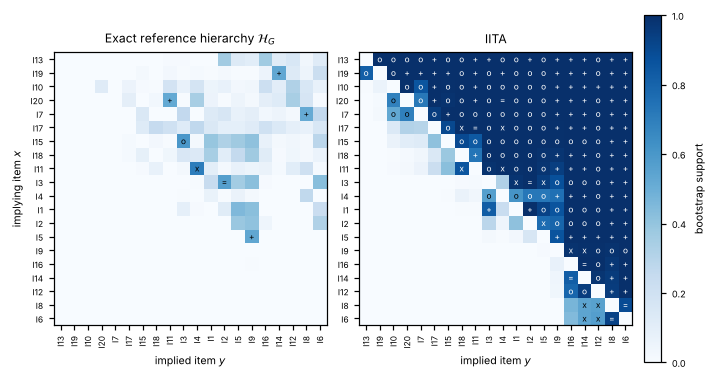

In [6]:
# import final_analysis
# final_analysis.main(("fraction",))
fig = real.fig_support()
plt.show()

## Command-line version

The same figures, with the file names used in the manuscript, are produced by

```bash
python3 code/make_figures.py --quick   # demonstration
python3 code/make_figures.py           # full protocol of Section 6.3
```